# Stage 4.5 — Candidate WOE Logistic Regression

This Notebook fits and diagnoses the fixed **10-variable Candidate WOE Logistic** on the full 24,000-row Train sample.

Boundaries: one unpenalized maximum-likelihood Logistic model with intercept; no variable deletion, alternate subset, regularization, class weighting/resampling, threshold optimization, calibration, cross-validation, or Test predictive analysis. Test is used only for the frozen row/ID/hash identity checks and is immediately deleted. All ten predictors continue to Stage 4.6 when the fixed model is numerically valid.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
sns.set_theme(style="whitegrid", context="notebook")

TARGET = "default.payment.next.month"
ID_COL = "ID"
RANDOM_STATE = 42
TEST_SIZE = 0.20
EXPECTED_TRAIN_HASH = "bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857"
EXPECTED_TEST_HASH = "d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f"
FINAL_PREDICTORS = [
    "PAY_0", "severe_delinquent_months",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "LIMIT_BAL", "avg_utilization",
]
PAY_VARIABLES = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_VARIABLES = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_VARIABLES = [f"PAY_AMT{i}" for i in range(1, 7)]
assert len(FINAL_PREDICTORS) == 10 and len(set(FINAL_PREDICTORS)) == 10

def locate_project_root():
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / "data/raw/UCI_Credit_Card.csv").is_file():
            return candidate
    raise FileNotFoundError("Formal raw CSV not found from launch path or its parents.")

def stable_id_hash(values):
    canonical = "\n".join(str(int(value)) for value in sorted(values))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

project_root = locate_project_root()
data_path = project_root / "data/raw/UCI_Credit_Card.csv"
environment_table = pd.DataFrame({
    "Value": [
        sys.executable,
        sys.version.split()[0],
        metadata.version("pandas"),
        metadata.version("numpy"),
        metadata.version("scipy"),
        metadata.version("scikit-learn"),
        metadata.version("matplotlib"),
        metadata.version("seaborn"),
        metadata.version("statsmodels"),
    ]
}, index=["Python executable", "Python version", "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "statsmodels"])
display(environment_table)
print("Project root:", project_root)
print("Frozen candidate order:", FINAL_PREDICTORS)


,Value
Python executable,/opt/anaconda3/bin/python
Python version,3.11.7
pandas,2.1.4
numpy,1.26.4
scipy,1.11.4
scikit-learn,1.2.2
matplotlib,3.8.0
seaborn,0.12.2
statsmodels,0.14.0


Project root: /Users/yu/2.工作/Risk Analysis Project
Frozen candidate order: ['PAY_0', 'severe_delinquent_months', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'LIMIT_BAL', 'avg_utilization']


## 1. Frozen split replay and permitted Test identity checks

The split is replayed with `random_state=42` and target stratification. The Test object is used only for row count, ID overlap/union coverage, and the frozen ID hash. No Test predictor distribution, Test target distribution, WOE, score, probability, risk relationship, or performance metric is inspected.


In [2]:
raw_df = pd.read_csv(data_path)
assert raw_df.shape == (30000, 25) and raw_df[ID_COL].is_unique

train_raw, sealed_test = train_test_split(
    raw_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=raw_df[TARGET],
)
train_ids = set(train_raw[ID_COL].astype(int))
test_ids = set(sealed_test[ID_COL].astype(int))
full_ids = set(raw_df[ID_COL].astype(int))
train_hash = stable_id_hash(train_ids)
test_hash = stable_id_hash(test_ids)
id_overlap = len(train_ids & test_ids)
id_union_complete = train_ids | test_ids == full_ids

assert len(train_raw) == 24000
assert len(sealed_test) == 6000
assert id_overlap == 0 and id_union_complete
assert train_hash == EXPECTED_TRAIN_HASH and test_hash == EXPECTED_TEST_HASH

split_evidence = pd.DataFrame({"Actual": [
    30000, len(train_raw), len(sealed_test), id_overlap, id_union_complete, train_hash, test_hash,
]}, index=[
    "Raw rows", "Train rows", "Test rows", "ID overlap", "Full ID union coverage",
    "Train ID SHA-256", "Test ID SHA-256",
])
display(split_evidence)

# Test sealing occurs immediately after the only permitted technical identity checks.
del sealed_test, test_ids, full_ids, raw_df
TEST_SEAL_STATUS = "SEALED — Test deleted after row/ID/union/hash identity checks only"
print(TEST_SEAL_STATUS)


,Actual
Raw rows,30000
Train rows,24000
Test rows,6000
ID overlap,0
Full ID union coverage,True
Train ID SHA-256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...
Test ID SHA-256,d6748249f9f9fb2855746e0ed980b5013047267104090a...


SEALED — Test deleted after row/ID/union/hash identity checks only


## 2. Reproduce only the required frozen Stage 3 features

- `severe_delinquent_months` is the count of the six raw PAY fields whose value is at least 2.
- `avg_utilization` is the mean of the six billing amounts after a calculation-local floor at zero, divided by `LIMIT_BAL`.
- Utilization above 1 is retained. No clipping, capping, or winsorization is applied.

No other engineered predictor is created for modeling.


In [3]:
train_work = train_raw.copy(deep=True)
index_before = train_work.index.copy()
ids_before = train_work[ID_COL].copy(deep=True)
target_before = train_work[TARGET].copy(deep=True)
raw_sources = PAY_VARIABLES + BILL_VARIABLES + PAY_AMT_VARIABLES + ["LIMIT_BAL"]
raw_sources_before = train_work[raw_sources].copy(deep=True)

pay_matrix = train_work[PAY_VARIABLES]
train_work["severe_delinquent_months"] = (pay_matrix >= 2).sum(axis=1).astype("int64")
assert (train_work["LIMIT_BAL"] > 0).all()
nonnegative_bills = train_work[BILL_VARIABLES].clip(lower=0)
train_work["avg_utilization"] = nonnegative_bills.mean(axis=1) / train_work["LIMIT_BAL"]
del nonnegative_bills

assert len(train_work) == 24000 and train_work.index.equals(index_before)
assert train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
pd.testing.assert_frame_equal(train_work[raw_sources], raw_sources_before, check_exact=True)
assert train_work[["severe_delinquent_months", "avg_utilization"]].notna().all().all()
assert np.isfinite(train_work["avg_utilization"]).all() and (train_work["avg_utilization"] >= 0).all()
assert (train_work["avg_utilization"] > 1).any()

TOTAL_GOOD = int((train_work[TARGET] == 0).sum())
TOTAL_BAD = int((train_work[TARGET] == 1).sum())
TRAIN_BAD_RATE = TOTAL_BAD / len(train_work)
assert (TOTAL_GOOD, TOTAL_BAD) == (18691, 5309)
feature_evidence = pd.DataFrame({"Result": [
    "PASS — 24,000 rows; ID/order/target unchanged",
    "PASS — raw PAY/BILL/PAY_AMT/LIMIT_BAL unchanged",
    "PASS — count(PAY_i >= 2) over the frozen six PAY fields",
    "PASS — mean(max(BILL_AMTi, 0)) / LIMIT_BAL; values above 1 retained",
    f"PASS — Good={TOTAL_GOOD:,}; Bad={TOTAL_BAD:,}; Bad rate={TRAIN_BAD_RATE:.6%}",
]}, index=["Alignment", "Raw-source integrity", "severe_delinquent_months", "avg_utilization", "Train target"])
display(feature_evidence)


,Result
Alignment,"PASS — 24,000 rows; ID/order/target unchanged"
Raw-source integrity,PASS — raw PAY/BILL/PAY_AMT/LIMIT_BAL unchanged
severe_delinquent_months,PASS — count(PAY_i >= 2) over the frozen six P...
avg_utilization,"PASS — mean(max(BILL_AMTi, 0)) / LIMIT_BAL; va..."
Train target,"PASS — Good=18,691; Bad=5,309; Bad rate=22.120..."


## 3. Apply the frozen Stage 4.2 and Stage 4.3 bins

Only the approved bins needed by the ten frozen candidates are applied. The mappings below reproduce the frozen Stage 4 sources; no cutpoint search, merging, or re-binning occurs.


In [4]:
PAY_DOMAIN = set(range(-2, 9))
PAY0_MAP = {
    -2: "[-2,-1,0]", -1: "[-2,-1,0]", 0: "[-2,-1,0]",
    1: "[1]", 2: "[2+]", 3: "[2+]", 4: "[2+]", 5: "[2+]",
    6: "[2+]", 7: "[2+]", 8: "[2+]",
}

def finite_number(value, name):
    if pd.isna(value) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise ValueError(f"{name}: invalid input")
    value = float(value)
    if not np.isfinite(value):
        raise ValueError(f"{name}: non-finite input")
    return value

def map_pay_0(value):
    numeric = finite_number(value, "PAY_0")
    raw = int(numeric)
    if raw != numeric or raw not in PAY_DOMAIN:
        raise ValueError("PAY_0 outside approved integer domain -2 through 8")
    return PAY0_MAP[raw]

def map_severe(value):
    numeric = finite_number(value, "severe_delinquent_months")
    raw = int(numeric)
    mapping = {0: "0", 1: "1", 2: "2", 3: "3", 4: "4+", 5: "4+", 6: "4+"}
    if raw != numeric or raw not in mapping:
        raise ValueError("severe_delinquent_months outside approved integer domain 0 through 6")
    return mapping[raw]

def map_payment(value):
    numeric = finite_number(value, "PAY_AMT")
    if numeric < 0:
        raise ValueError("negative PAY_AMT outside approved domain")
    if numeric == 0:
        return "0"
    if numeric <= 5000:
        return "(0,5k]"
    if numeric <= 20000:
        return "(5k,20k]"
    return ">20k"

def map_limit(value):
    numeric = finite_number(value, "LIMIT_BAL")
    if numeric <= 30000:
        return "<=30k"
    if numeric <= 140000:
        return "(30k,140k]"
    if numeric <= 240000:
        return "(140k,240k]"
    return ">240k"

def map_utilization(value):
    numeric = finite_number(value, "avg_utilization")
    if numeric < 0:
        raise ValueError("negative utilization outside approved domain")
    if numeric == 0:
        return "0"
    if numeric <= 0.20:
        return "(0,0.2]"
    if numeric <= 0.60:
        return "(0.2,0.6]"
    if numeric <= 1:
        return "(0.6,1]"
    return ">1"

BIN_ORDERS = {
    "PAY_0": ["[-2,-1,0]", "[1]", "[2+]"],
    "severe_delinquent_months": ["0", "1", "2", "3", "4+"],
    **{name: ["0", "(0,5k]", "(5k,20k]", ">20k"] for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": ["<=30k", "(30k,140k]", "(140k,240k]", ">240k"],
    "avg_utilization": ["0", "(0,0.2]", "(0.2,0.6]", "(0.6,1]", ">1"],
}
BIN_MAPPERS = {
    "PAY_0": map_pay_0,
    "severe_delinquent_months": map_severe,
    **{name: map_payment for name in PAY_AMT_VARIABLES},
    "LIMIT_BAL": map_limit,
    "avg_utilization": map_utilization,
}
assert list(BIN_ORDERS) == FINAL_PREDICTORS and list(BIN_MAPPERS) == FINAL_PREDICTORS

for predictor in FINAL_PREDICTORS:
    bin_column = f"{predictor}_BIN"
    labels = train_work[predictor].map(BIN_MAPPERS[predictor])
    train_work[bin_column] = pd.Categorical(labels, categories=BIN_ORDERS[predictor], ordered=True)
    assert train_work[bin_column].notna().all()

assert train_work.index.equals(index_before)
assert train_work[ID_COL].equals(ids_before) and train_work[TARGET].equals(target_before)
pd.testing.assert_frame_equal(train_work[raw_sources], raw_sources_before, check_exact=True)
print("PASS — exactly ten frozen mappings applied in canonical order; no source value changed.")


PASS — exactly ten frozen mappings applied in canonical order; no source value changed.


## 4. Full-Train WOE estimation and exact 24,000 × 10 matrix

For each frozen bin, WOE is estimated on the full Train sample as:

\[
WOE_j = \ln\left(\frac{DistGood_j}{DistBad_j}\right),\quad Good=(Default=0),\ Bad=(Default=1).
\]

All final bins contain both classes, so no smoothing is required or used.


In [5]:
EXPECTED_FINAL_IV = {
    "PAY_0": 0.872145621429,
    "severe_delinquent_months": 0.846474512620,
    "PAY_AMT1": 0.175537864049,
    "PAY_AMT2": 0.151113586876,
    "PAY_AMT3": 0.121957912222,
    "PAY_AMT4": 0.088405981704,
    "PAY_AMT5": 0.075093140327,
    "PAY_AMT6": 0.079904481549,
    "LIMIT_BAL": 0.190444892886,
    "avg_utilization": 0.121261375406,
}
assert list(EXPECTED_FINAL_IV) == FINAL_PREDICTORS

woe_tables = {}
woe_matrix = pd.DataFrame(index=train_work.index)
iv_totals = {}

for predictor in FINAL_PREDICTORS:
    bin_column = f"{predictor}_BIN"
    grouped = train_work.groupby(bin_column, observed=True)[TARGET].agg(Count="size", Bad="sum")
    grouped = grouped.loc[BIN_ORDERS[predictor]]
    grouped["Good"] = grouped["Count"] - grouped["Bad"]
    table = grouped.reset_index().rename(columns={bin_column: "Final Bin"})
    table["% Train"] = table["Count"] / len(train_work)
    table["Default Rate"] = table["Bad"] / table["Count"]
    table["Dist Good"] = table["Good"] / TOTAL_GOOD
    table["Dist Bad"] = table["Bad"] / TOTAL_BAD
    table["WOE"] = np.log(table["Dist Good"] / table["Dist Bad"])
    table["IV Contribution"] = (table["Dist Good"] - table["Dist Bad"]) * table["WOE"]

    assert int(table["Count"].sum()) == 24000
    assert int(table["Good"].sum()) == 18691 and int(table["Bad"].sum()) == 5309
    assert (table["Good"] > 0).all() and (table["Bad"] > 0).all()
    assert np.isfinite(table[["WOE", "IV Contribution"]].to_numpy()).all()

    woe_tables[predictor] = table
    total_iv = float(table["IV Contribution"].sum())
    assert np.isclose(total_iv, EXPECTED_FINAL_IV[predictor], atol=5e-12, rtol=0), (predictor, total_iv)
    iv_totals[predictor] = total_iv
    lookup = table.set_index("Final Bin")["WOE"]
    woe_matrix[predictor] = train_work[bin_column].map(lookup).astype(float)

assert woe_matrix.shape == (24000, 10)
assert woe_matrix.columns.tolist() == FINAL_PREDICTORS
assert woe_matrix.index.equals(train_work.index)
assert woe_matrix.isna().sum().sum() == 0
assert np.isfinite(woe_matrix.to_numpy()).all()
assert train_work[TARGET].equals(target_before) and train_work[ID_COL].equals(ids_before)

woe_rerun = pd.DataFrame({
    predictor: train_work[f"{predictor}_BIN"].map(
        woe_tables[predictor].set_index("Final Bin")["WOE"]
    ).astype(float)
    for predictor in FINAL_PREDICTORS
}, index=train_work.index)
pd.testing.assert_frame_equal(woe_matrix, woe_rerun, check_exact=True)
del woe_rerun

matrix_evidence = pd.DataFrame({"Actual": [
    woe_matrix.shape,
    woe_matrix.columns.tolist() == FINAL_PREDICTORS,
    int(woe_matrix.isna().sum().sum()),
    int((~np.isfinite(woe_matrix.to_numpy())).sum()),
    woe_matrix.index.equals(train_work.index),
    train_work[TARGET].equals(target_before),
    False,
]}, index=["Shape", "Canonical order", "Missing", "Non-finite", "Row alignment", "Target alignment", "Smoothing used"])
display(matrix_evidence)
display(pd.DataFrame({"Full-Train IV (context only)": iv_totals}).rename_axis("Predictor"))


,Actual
Shape,"(24000, 10)"
Canonical order,True
Missing,0
Non-finite,0
Row alignment,True
Target alignment,True
Smoothing used,False


,Full-Train IV (context only)
Predictor,
LIMIT_BAL,0.190445
PAY_0,0.872146
PAY_AMT1,0.175538
PAY_AMT2,0.151114
PAY_AMT3,0.121958
PAY_AMT4,0.088406
PAY_AMT5,0.075093
PAY_AMT6,0.079904
avg_utilization,0.121261


## 5. WOE convention and expected Logistic coefficient sign

Positive WOE is relatively safer under `ln(DistGood / DistBad)`. With `Default=1` as the Logistic target, a conventionally behaving WOE predictor is therefore expected to have a **negative** coefficient: higher/safer WOE should lower default log-odds.


## 6. Fixed unpenalized maximum-likelihood Logistic model

One substantive predictive model is fitted: `statsmodels.Logit` with an intercept and all ten WOE predictors simultaneously. This is genuine unpenalized maximum likelihood on the natural Train sample. Standard errors, z-statistics, p-values, confidence intervals, and covariance are taken from the fitted MLE result. No alternative model is fitted.


In [6]:
y_train = train_work[TARGET].astype(int).copy()
assert y_train.index.equals(woe_matrix.index) and set(y_train.unique()) == {0, 1}
X_model = sm.add_constant(woe_matrix, has_constant="add")
assert X_model.columns.tolist() == ["const", *FINAL_PREDICTORS]
assert np.linalg.matrix_rank(X_model.to_numpy()) == 11

with warnings.catch_warnings(record=True) as fit_warning_records:
    warnings.simplefilter("always")
    candidate_model = sm.Logit(y_train, X_model)
    candidate_result = candidate_model.fit(method="newton", maxiter=100, disp=False)

FIT_WARNINGS = [f"{record.category.__name__}: {record.message}" for record in fit_warning_records]
converged = bool(candidate_result.mle_retvals.get("converged", False))
iterations = int(candidate_result.mle_retvals.get("iterations", -1))
params = candidate_result.params
standard_errors = candidate_result.bse
covariance = candidate_result.cov_params()
linear_predictor = X_model.to_numpy(dtype=float) @ params.to_numpy(dtype=float)
predicted_probability = candidate_result.predict(X_model)
summary_text = candidate_result.summary().as_text().lower()

covariance_symmetric = bool(np.allclose(covariance, covariance.T, atol=1e-12, rtol=1e-10))
covariance_min_eigenvalue = float(np.linalg.eigvalsh(covariance.to_numpy(dtype=float)).min())
covariance_condition_number = float(np.linalg.cond(covariance.to_numpy(dtype=float)))
invalid_warning_terms = ("separation", "singular", "overflow", "underflow")
invalid_fit_warning = any(term in warning.lower() for warning in FIT_WARNINGS for term in invalid_warning_terms)
summary_separation_flag = "separation" in summary_text

numerical_checks = {
    "Model converged": converged,
    "Design rank = 11": np.linalg.matrix_rank(X_model.to_numpy()) == 11,
    "Intercept and all coefficients finite": bool(np.isfinite(params.to_numpy()).all()),
    "All standard errors finite and positive": bool(np.isfinite(standard_errors.to_numpy()).all() and (standard_errors > 0).all()),
    "Covariance finite": bool(np.isfinite(covariance.to_numpy()).all()),
    "Covariance symmetric": covariance_symmetric,
    "Covariance positive definite": covariance_min_eigenvalue > 0,
    "Covariance condition number finite": np.isfinite(covariance_condition_number),
    "Linear predictor finite": bool(np.isfinite(linear_predictor).all()),
    "Predicted probabilities finite": bool(np.isfinite(predicted_probability).all()),
    "Probabilities strictly within (0, 1)": bool(((predicted_probability > 0) & (predicted_probability < 1)).all()),
    "No invalidating fit warning": not invalid_fit_warning,
    "No separation warning in model summary": not summary_separation_flag,
}
INFERENCE_NUMERICALLY_VALID = all(numerical_checks.values())
assert INFERENCE_NUMERICALLY_VALID

sanity_table = pd.DataFrame({
    "Result": ["PASS" if passed else "FAIL" for passed in numerical_checks.values()]
}, index=numerical_checks.keys())
display(sanity_table)
model_fit_evidence = pd.DataFrame({"Actual": [
    "statsmodels.Logit",
    "Unpenalized maximum likelihood",
    True,
    len(y_train),
    converged,
    iterations,
    len(FIT_WARNINGS),
    float(params["const"]),
    float(predicted_probability.min()),
    float(predicted_probability.max()),
    covariance_min_eigenvalue,
    covariance_condition_number,
]}, index=[
    "Implementation", "Estimator", "Intercept included", "Train rows", "Converged",
    "Iterations", "Warning count", "Intercept", "Minimum probability", "Maximum probability",
    "Covariance minimum eigenvalue", "Covariance condition number",
])
display(model_fit_evidence)
print("Fit warnings:", FIT_WARNINGS if FIT_WARNINGS else "None")


,Result
Model converged,PASS
Design rank = 11,PASS
Intercept and all coefficients finite,PASS
All standard errors finite and positive,PASS
Covariance finite,PASS
Covariance symmetric,PASS
Covariance positive definite,PASS
Covariance condition number finite,PASS
Linear predictor finite,PASS
Predicted probabilities finite,PASS


,Actual
Implementation,statsmodels.Logit
Estimator,Unpenalized maximum likelihood
Intercept included,True
Train rows,24000
Converged,True
Iterations,6
Warning count,0
Intercept,-1.254276
Minimum probability,0.038073
Maximum probability,0.867665


Fit warnings: None


## 7. Canonical coefficient diagnostic table

For each WOE predictor, `z = coefficient / standard error`, the 95% confidence interval and p-value are inferential outputs from the unpenalized MLE, and `Odds Ratio = exp(coefficient)` is the multiplicative change in default odds for a one-unit increase in that WOE predictor while holding the other predictors constant. It is not a percentage change in default probability and is not used as a selection rule.

Diagnostic status rules are deterministic and observational only:

- **Directionally Clear**: coefficient < 0 and the entire 95% CI is below 0.
- **Review in Stage 4.6**: coefficient is non-positive but its 95% CI includes 0.
- **Sign Concern**: coefficient > 0, regardless of significance.

No z-, p-value-, CI-, sign-, OR-, AUC-, or KS-based deletion occurs.


In [7]:
confidence = candidate_result.conf_int(alpha=0.05)

def diagnostic_status(coefficient, ci_upper):
    if coefficient > 0:
        return "Sign Concern"
    if ci_upper < 0:
        return "Directionally Clear"
    return "Review in Stage 4.6"

def follow_up_note(predictor, status):
    if status == "Sign Concern":
        return "Continue to Stage 4.6 — prioritize fold sign/CI stability; no deletion."
    if status == "Review in Stage 4.6":
        return "Continue to Stage 4.6 — prioritize conditional-contribution stability; no deletion."
    if predictor in {"PAY_0", "severe_delinquent_months"}:
        return "Continue to Stage 4.6 — verify current vs persistent delinquency stability."
    if predictor in PAY_AMT_VARIABLES:
        return "Continue to Stage 4.6 — verify monthly-payment coefficient stability."
    return "Continue to Stage 4.6 — verify coefficient and uncertainty stability."

coefficient_rows = []
for predictor in FINAL_PREDICTORS:
    coefficient = float(params[predictor])
    ci_lower = float(confidence.loc[predictor, 0])
    ci_upper = float(confidence.loc[predictor, 1])
    status = diagnostic_status(coefficient, ci_upper)
    coefficient_rows.append({
        "Predictor": predictor,
        "Coefficient": coefficient,
        "Expected Sign": "Negative",
        "Sign Check": "Expected" if coefficient < 0 else "Sign Concern" if coefficient > 0 else "Review",
        "Standard Error": float(standard_errors[predictor]),
        "z-statistic": float(candidate_result.tvalues[predictor]),
        "p-value": float(candidate_result.pvalues[predictor]),
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Odds Ratio": float(np.exp(coefficient)),
        "Full-Train Diagnostic Status": status,
        "Stage 4.6 Follow-up Note": follow_up_note(predictor, status),
    })

coefficient_table = pd.DataFrame(coefficient_rows)
assert coefficient_table.shape == (10, 12)
assert coefficient_table["Predictor"].tolist() == FINAL_PREDICTORS
assert np.isfinite(coefficient_table[[
    "Coefficient", "Standard Error", "z-statistic", "p-value",
    "95% CI Lower", "95% CI Upper", "Odds Ratio",
]].to_numpy()).all()
display(coefficient_table.style.format({
    "Coefficient": "{:.6f}", "Standard Error": "{:.6f}", "z-statistic": "{:.4f}",
    "p-value": "{:.6g}", "95% CI Lower": "{:.6f}", "95% CI Upper": "{:.6f}",
    "Odds Ratio": "{:.6f}",
}))


,Predictor,Coefficient,Expected Sign,Sign Check,Standard Error,z-statistic,p-value,95% CI Lower,95% CI Upper,Odds Ratio,Full-Train Diagnostic Status,Stage 4.6 Follow-up Note
0,PAY_0,-0.556304,Negative,Expected,0.023615,-23.5571,1.06187e-122,-0.602588,-0.510019,0.573324,Directionally Clear,Continue to Stage 4.6 — verify current vs persistent delinquency stability.
1,severe_delinquent_months,-0.513060,Negative,Expected,0.024386,-21.0389,2.88949e-98,-0.560856,-0.465264,0.598661,Directionally Clear,Continue to Stage 4.6 — verify current vs persistent delinquency stability.
2,PAY_AMT1,-0.193756,Negative,Expected,0.048841,-3.9671,7.27532e-05,-0.289481,-0.098030,0.823859,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.
3,PAY_AMT2,-0.222093,Negative,Expected,0.054644,-4.0643,4.81711e-05,-0.329194,-0.114992,0.800841,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.
4,PAY_AMT3,-0.245401,Negative,Expected,0.062021,-3.9568,7.59746e-05,-0.366960,-0.123843,0.782390,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.
5,PAY_AMT4,-0.165042,Negative,Expected,0.072426,-2.2788,0.0226804,-0.306993,-0.023090,0.847858,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.
6,PAY_AMT5,-0.097122,Negative,Expected,0.078560,-1.2363,0.21635,-0.251096,0.056851,0.907445,Review in Stage 4.6,Continue to Stage 4.6 — prioritize conditional-contribution stability; no deletion.
7,PAY_AMT6,-0.164349,Negative,Expected,0.078065,-2.1053,0.0352658,-0.317353,-0.011345,0.848446,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.
8,LIMIT_BAL,-0.226161,Negative,Expected,0.044958,-5.0305,4.89151e-07,-0.314276,-0.138045,0.797590,Directionally Clear,Continue to Stage 4.6 — verify coefficient and uncertainty stability.
9,avg_utilization,-0.405621,Negative,Expected,0.052466,-7.7312,1.0656e-14,-0.508452,-0.302790,0.666563,Directionally Clear,Continue to Stage 4.6 — verify coefficient and uncertainty stability.


## LOG-01 — Candidate WOE Logistic coefficient forest plot

Point estimates and 95% confidence intervals are shown in canonical predictor order. The zero line is a diagnostic reference, not a Keep/Drop rule.


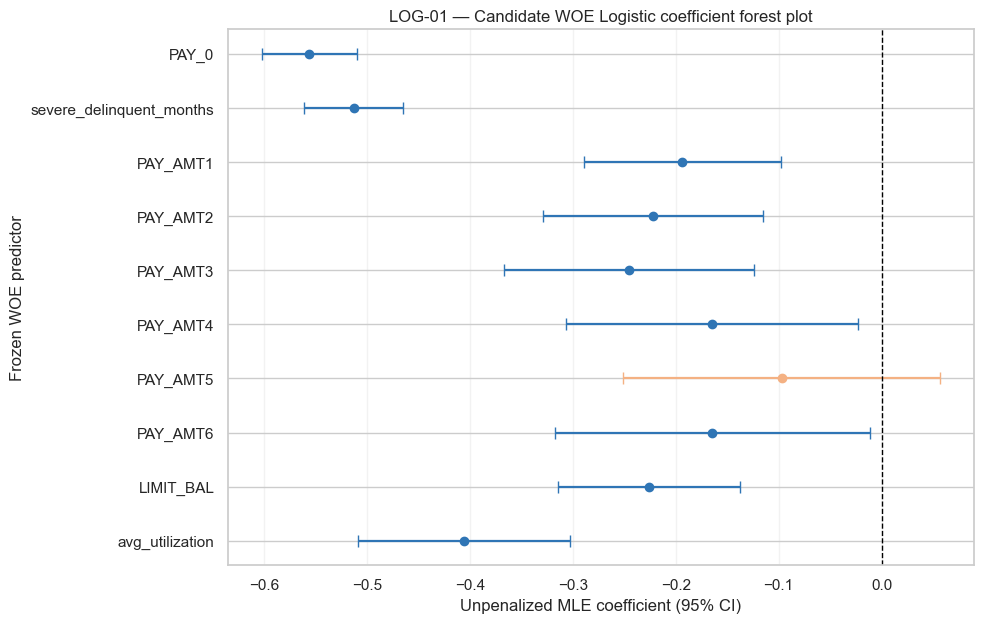

In [8]:
plot_table = coefficient_table.set_index("Predictor").loc[FINAL_PREDICTORS]
y_position = np.arange(len(FINAL_PREDICTORS))
coefficient_values = plot_table["Coefficient"].to_numpy()
lower_error = coefficient_values - plot_table["95% CI Lower"].to_numpy()
upper_error = plot_table["95% CI Upper"].to_numpy() - coefficient_values
status_colors = {
    "Directionally Clear": "#2F75B5",
    "Review in Stage 4.6": "#F4B183",
    "Sign Concern": "#C00000",
}
point_colors = [status_colors[value] for value in plot_table["Full-Train Diagnostic Status"]]

fig, ax = plt.subplots(figsize=(10, 6.4))
for row, predictor in enumerate(FINAL_PREDICTORS):
    ax.errorbar(
        coefficient_values[row], row,
        xerr=np.array([[lower_error[row]], [upper_error[row]]]),
        fmt="o", color=point_colors[row], ecolor=point_colors[row],
        capsize=4, markersize=6, linewidth=1.6,
    )
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y_position, FINAL_PREDICTORS)
ax.invert_yaxis()
ax.set_xlabel("Unpenalized MLE coefficient (95% CI)")
ax.set_ylabel("Frozen WOE predictor")
ax.set_title("LOG-01 — Candidate WOE Logistic coefficient forest plot")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
LOG_01_STATUS = "PRESENT — inline coefficient forest plot with 10 estimates, 95% CIs, and zero reference"


## 8. PAY / delinquency conditional diagnostic

`PAY_0` represents recent/current delinquency status and `severe_delinquent_months` represents persistence of serious delinquency across the six frozen PAY months. Their conditional directions and uncertainty are inspected together without reopening any dropped PAY representation.


In [9]:
pay_delinquency_diagnostic = coefficient_table.loc[
    coefficient_table["Predictor"].isin(["PAY_0", "severe_delinquent_months"]),
    ["Predictor", "Coefficient", "Sign Check", "Standard Error", "95% CI Lower", "95% CI Upper", "p-value", "Full-Train Diagnostic Status"],
].copy()
pay_delinquency_diagnostic["Predictor"] = pd.Categorical(
    pay_delinquency_diagnostic["Predictor"],
    categories=["PAY_0", "severe_delinquent_months"],
    ordered=True,
)
pay_delinquency_diagnostic = pay_delinquency_diagnostic.sort_values("Predictor")
display(pay_delinquency_diagnostic)
print("Interpretation boundary: conditional full-Train evidence only; both variables continue to Stage 4.6.")


,Predictor,Coefficient,Sign Check,Standard Error,95% CI Lower,95% CI Upper,p-value,Full-Train Diagnostic Status
0,PAY_0,-0.556304,Expected,0.023615,-0.602588,-0.510019,0.000000,Directionally Clear
1,severe_delinquent_months,-0.513060,Expected,0.024386,-0.560856,-0.465264,0.000000,Directionally Clear


Interpretation boundary: conditional full-Train evidence only; both variables continue to Stage 4.6.


## 9. PAY_AMT1–6 conditional diagnostic

All six frozen monthly payment predictors remain in the single model. Their coefficient, direction, uncertainty, and p-value are recorded; no month is deleted and no aggregate/trend replacement is created.


In [10]:
payment_diagnostic = coefficient_table.loc[
    coefficient_table["Predictor"].isin(PAY_AMT_VARIABLES),
    ["Predictor", "Coefficient", "Sign Check", "Standard Error", "95% CI Lower", "95% CI Upper", "p-value", "Full-Train Diagnostic Status"],
].set_index("Predictor").loc[PAY_AMT_VARIABLES].reset_index()
display(payment_diagnostic)
print("Interpretation boundary: joint monthly-payment behavior is diagnostic; all six continue to Stage 4.6.")


,Predictor,Coefficient,Sign Check,Standard Error,95% CI Lower,95% CI Upper,p-value,Full-Train Diagnostic Status
0,PAY_AMT1,-0.193756,Expected,0.048841,-0.289481,-0.098030,0.000073,Directionally Clear
1,PAY_AMT2,-0.222093,Expected,0.054644,-0.329194,-0.114992,0.000048,Directionally Clear
2,PAY_AMT3,-0.245401,Expected,0.062021,-0.366960,-0.123843,0.000076,Directionally Clear
3,PAY_AMT4,-0.165042,Expected,0.072426,-0.306993,-0.023090,0.022680,Directionally Clear
4,PAY_AMT5,-0.097122,Expected,0.078560,-0.251096,0.056851,0.216350,Review in Stage 4.6
5,PAY_AMT6,-0.164349,Expected,0.078065,-0.317353,-0.011345,0.035266,Directionally Clear


Interpretation boundary: joint monthly-payment behavior is diagnostic; all six continue to Stage 4.6.


## 10. LIMIT_BAL / avg_utilization conditional diagnostic

These frozen capacity and sustained-utilization representations are inspected while controlling for delinquency and payment behavior. Dropped utilization and BILL representations are not reopened.


In [11]:
capacity_utilization_diagnostic = coefficient_table.loc[
    coefficient_table["Predictor"].isin(["LIMIT_BAL", "avg_utilization"]),
    ["Predictor", "Coefficient", "Sign Check", "Standard Error", "95% CI Lower", "95% CI Upper", "p-value", "Full-Train Diagnostic Status"],
].copy()
capacity_utilization_diagnostic["Predictor"] = pd.Categorical(
    capacity_utilization_diagnostic["Predictor"],
    categories=["LIMIT_BAL", "avg_utilization"],
    ordered=True,
)
capacity_utilization_diagnostic = capacity_utilization_diagnostic.sort_values("Predictor")
display(capacity_utilization_diagnostic)
print("Interpretation boundary: conditional full-Train evidence only; both variables continue to Stage 4.6.")


,Predictor,Coefficient,Sign Check,Standard Error,95% CI Lower,95% CI Upper,p-value,Full-Train Diagnostic Status
8,LIMIT_BAL,-0.226161,Expected,0.044958,-0.314276,-0.138045,0.000000,Directionally Clear
9,avg_utilization,-0.405621,Expected,0.052466,-0.508452,-0.302790,0.000000,Directionally Clear


Interpretation boundary: conditional full-Train evidence only; both variables continue to Stage 4.6.


## 11. Apparent full-Train AUC and LOG-02

This is an **apparent development-sample AUC**, calculated from the same full Train sample used to estimate the frozen-bin WOE values and Logistic coefficients. It is not an estimate of generalization performance, is not Holdout evidence, and is not used for feature elimination or model search.


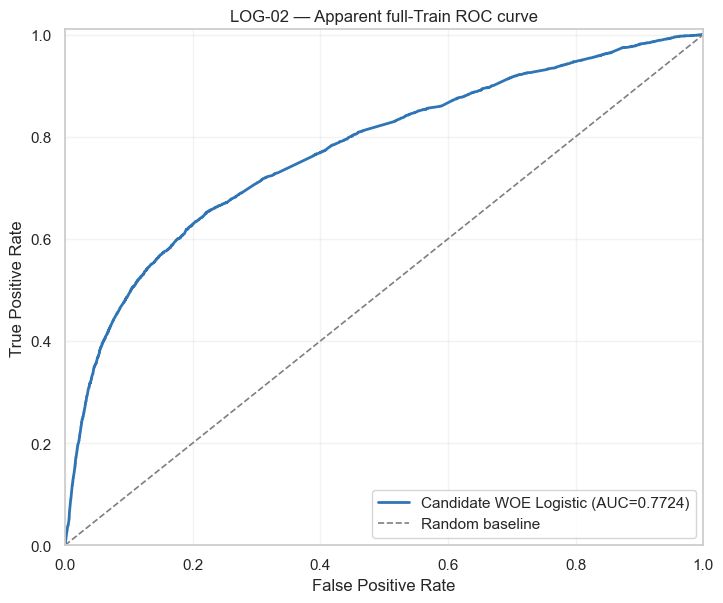

Apparent development-sample AUC: 0.772417


In [12]:
fpr, tpr, roc_thresholds = roc_curve(y_train, predicted_probability, pos_label=1)
apparent_train_auc = float(roc_auc_score(y_train, predicted_probability))
assert np.isfinite(apparent_train_auc) and 0 <= apparent_train_auc <= 1

fig, ax = plt.subplots(figsize=(7.4, 6.2))
ax.plot(fpr, tpr, color="#2F75B5", linewidth=2.0, label=f"Candidate WOE Logistic (AUC={apparent_train_auc:.4f})")
ax.plot([0, 1], [0, 1], color="#7F7F7F", linestyle="--", linewidth=1.2, label="Random baseline")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("LOG-02 — Apparent full-Train ROC curve")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
LOG_02_STATUS = "PRESENT — inline apparent full-Train ROC curve with AUC and random baseline"
print(f"Apparent development-sample AUC: {apparent_train_auc:.6f}")


## 12. Apparent full-Train KS and LOG-03

KS is defined deterministically from the full-Train ROC quantities as `max(TPR − FPR)`, with `Default=1` and predicted default probability as the score. The threshold at maximum KS is reported only as a diagnostic location; it is not an approved or optimized operational decision threshold.


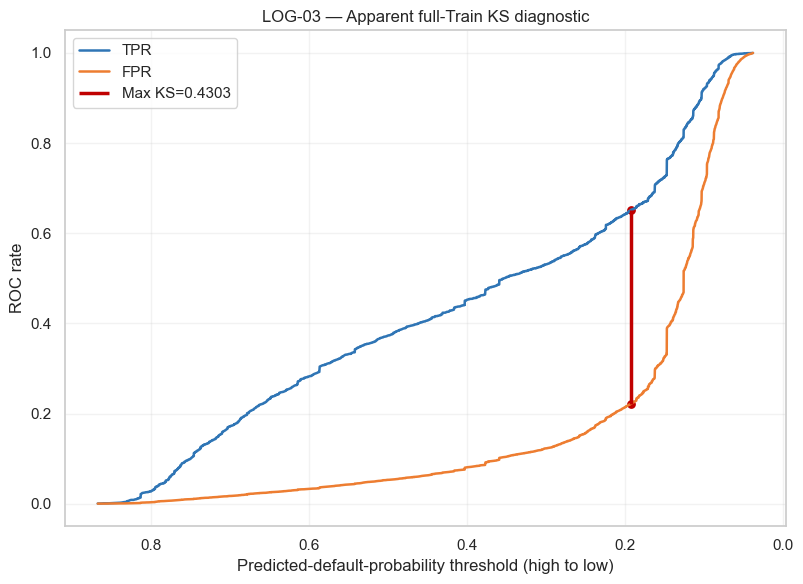

Apparent development-sample KS: 0.430308
KS-max threshold (diagnostic location only): 0.192435


In [13]:
ks_gap = tpr - fpr
ks_index = int(np.argmax(ks_gap))
apparent_train_ks = float(ks_gap[ks_index])
ks_diagnostic_threshold = float(roc_thresholds[ks_index])
assert np.isfinite(apparent_train_ks) and 0 <= apparent_train_ks <= 1
assert np.isfinite(ks_diagnostic_threshold)

finite_threshold_mask = np.isfinite(roc_thresholds) & (roc_thresholds >= 0) & (roc_thresholds <= 1)
threshold_x = roc_thresholds[finite_threshold_mask]
tpr_finite = tpr[finite_threshold_mask]
fpr_finite = fpr[finite_threshold_mask]

fig, ax = plt.subplots(figsize=(8.2, 6.0))
ax.plot(threshold_x, tpr_finite, color="#2F75B5", linewidth=1.8, label="TPR")
ax.plot(threshold_x, fpr_finite, color="#ED7D31", linewidth=1.8, label="FPR")
ax.vlines(
    ks_diagnostic_threshold,
    fpr[ks_index],
    tpr[ks_index],
    color="#C00000",
    linewidth=2.5,
    label=f"Max KS={apparent_train_ks:.4f}",
)
ax.scatter([ks_diagnostic_threshold, ks_diagnostic_threshold], [fpr[ks_index], tpr[ks_index]], color="#C00000", s=28)
ax.invert_xaxis()
ax.set_xlabel("Predicted-default-probability threshold (high to low)")
ax.set_ylabel("ROC rate")
ax.set_title("LOG-03 — Apparent full-Train KS diagnostic")
ax.legend(loc="best")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
LOG_03_STATUS = "PRESENT — inline apparent full-Train TPR/FPR separation with maximum KS highlighted"
print(f"Apparent development-sample KS: {apparent_train_ks:.6f}")
print(f"KS-max threshold (diagnostic location only): {ks_diagnostic_threshold:.6f}")


## 13. Performance-evidence hierarchy

`Full Train apparent → Stage 4.6 cross-validation → Stage 5 final Holdout`

- **Stage 4.5:** apparent full-Train diagnostics only.
- **Stage 4.6:** out-of-fold stability and predictive evidence.
- **Stage 5:** sealed Holdout Test evaluation.

The AUC and KS above must not be presented as final expected performance.


In [14]:
evidence_hierarchy = pd.DataFrame({
    "Evidence": [
        "Apparent development-sample diagnostics",
        "Out-of-fold stability / predictive evidence",
        "Sealed Holdout Test evaluation",
    ],
    "Available in Stage 4.5?": ["Yes", "No", "No"],
    "Use": ["Diagnosis only", "Future Stage 4.6", "Future Stage 5"],
}, index=["Stage 4.5", "Stage 4.6", "Stage 5"])
display(evidence_hierarchy)


,Evidence,Available in Stage 4.5?,Use
Stage 4.5,Apparent development-sample diagnostics,Yes,Diagnosis only
Stage 4.6,Out-of-fold stability / predictive evidence,No,Future Stage 4.6
Stage 5,Sealed Holdout Test evaluation,No,Future Stage 5


## 14. Stage 4.6 handoff — all ten continue

This handoff contains no Keep/Drop decision and does not freeze a final model structure. Every predictor continues to Stage 4.6 because the complete fixed model passed the numerical-validity gate.


In [15]:
handoff_table = coefficient_table[[
    "Predictor", "Coefficient", "95% CI Lower", "95% CI Upper", "p-value",
    "Full-Train Diagnostic Status", "Stage 4.6 Follow-up Note",
]].copy()
handoff_table = handoff_table.rename(columns={
    "Coefficient": "Full-Train Coefficient",
    "Full-Train Diagnostic Status": "Stage 4.5 Diagnostic Status",
    "Stage 4.6 Follow-up Note": "Stage 4.6 Follow-up Priority / Note",
})
handoff_table.insert(
    2,
    "Sign",
    np.where(handoff_table["Full-Train Coefficient"] < 0, "Negative", np.where(handoff_table["Full-Train Coefficient"] > 0, "Positive", "Zero")),
)
handoff_table.insert(
    5,
    "95% CI",
    handoff_table.apply(lambda row: f"[{row['95% CI Lower']:.6f}, {row['95% CI Upper']:.6f}]", axis=1),
)
handoff_table = handoff_table.drop(columns=["95% CI Lower", "95% CI Upper"])
handoff_table["Continuation"] = "Continue to Stage 4.6"
assert handoff_table.shape[0] == 10
assert handoff_table["Predictor"].tolist() == FINAL_PREDICTORS
assert handoff_table["Continuation"].eq("Continue to Stage 4.6").all()
display(handoff_table.style.format({"Full-Train Coefficient": "{:.6f}", "p-value": "{:.6g}"}))


,Predictor,Full-Train Coefficient,Sign,95% CI,p-value,Stage 4.5 Diagnostic Status,Stage 4.6 Follow-up Priority / Note,Continuation
0,PAY_0,-0.556304,Negative,"[-0.602588, -0.510019]",1.06187e-122,Directionally Clear,Continue to Stage 4.6 — verify current vs persistent delinquency stability.,Continue to Stage 4.6
1,severe_delinquent_months,-0.513060,Negative,"[-0.560856, -0.465264]",2.88949e-98,Directionally Clear,Continue to Stage 4.6 — verify current vs persistent delinquency stability.,Continue to Stage 4.6
2,PAY_AMT1,-0.193756,Negative,"[-0.289481, -0.098030]",7.27532e-05,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.,Continue to Stage 4.6
3,PAY_AMT2,-0.222093,Negative,"[-0.329194, -0.114992]",4.81711e-05,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.,Continue to Stage 4.6
4,PAY_AMT3,-0.245401,Negative,"[-0.366960, -0.123843]",7.59746e-05,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.,Continue to Stage 4.6
5,PAY_AMT4,-0.165042,Negative,"[-0.306993, -0.023090]",0.0226804,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.,Continue to Stage 4.6
6,PAY_AMT5,-0.097122,Negative,"[-0.251096, 0.056851]",0.21635,Review in Stage 4.6,Continue to Stage 4.6 — prioritize conditional-contribution stability; no deletion.,Continue to Stage 4.6
7,PAY_AMT6,-0.164349,Negative,"[-0.317353, -0.011345]",0.0352658,Directionally Clear,Continue to Stage 4.6 — verify monthly-payment coefficient stability.,Continue to Stage 4.6
8,LIMIT_BAL,-0.226161,Negative,"[-0.314276, -0.138045]",4.89151e-07,Directionally Clear,Continue to Stage 4.6 — verify coefficient and uncertainty stability.,Continue to Stage 4.6
9,avg_utilization,-0.405621,Negative,"[-0.508452, -0.302790]",1.0656e-14,Directionally Clear,Continue to Stage 4.6 — verify coefficient and uncertainty stability.,Continue to Stage 4.6


## 15. Final implementation boundary and machine-verifiable summary

The result remains the **Stage 4.5 fixed 10-variable Candidate WOE Logistic**, not a final Logistic predictor list. There was no automatic deletion, alternative subset search, regularization, class weighting/resampling, threshold optimization, calibration, cross-validation, or Test predictive analysis.


In [16]:
status_counts = coefficient_table["Full-Train Diagnostic Status"].value_counts().to_dict()
coefficient_signs = {
    row["Predictor"]: "Negative" if row["Coefficient"] < 0 else "Positive" if row["Coefficient"] > 0 else "Zero"
    for row in coefficient_rows
}
expected_sign_count = sum(sign == "Negative" for sign in coefficient_signs.values())
sign_concern_count = sum(sign == "Positive" for sign in coefficient_signs.values())
ci_crosses_zero_count = int(((coefficient_table["95% CI Lower"] <= 0) & (coefficient_table["95% CI Upper"] >= 0)).sum())

assert len(coefficient_signs) == 10
assert sum(status_counts.values()) == 10
assert handoff_table["Continuation"].eq("Continue to Stage 4.6").all()
assert INFERENCE_NUMERICALLY_VALID

stage45_results = {
    "project_root": str(project_root),
    "python_executable": sys.executable,
    "python_version": sys.version.split()[0],
    "package_versions": {name: metadata.version(name) for name in [
        "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "statsmodels"
    ]},
    "raw_rows": 30000,
    "train_rows": len(train_work),
    "test_rows_identity_only": 6000,
    "train_id_sha256": train_hash,
    "test_id_sha256": test_hash,
    "test_seal_status": TEST_SEAL_STATUS,
    "train_good": TOTAL_GOOD,
    "train_bad": TOTAL_BAD,
    "train_bad_rate": TRAIN_BAD_RATE,
    "predictors": FINAL_PREDICTORS,
    "woe_convention": "ln(DistGood / DistBad)",
    "woe_matrix_shape": list(woe_matrix.shape),
    "woe_missing": int(woe_matrix.isna().sum().sum()),
    "woe_non_finite": int((~np.isfinite(woe_matrix.to_numpy())).sum()),
    "smoothing_used": False,
    "model_implementation": "statsmodels.Logit unpenalized maximum likelihood with intercept",
    "model_converged": converged,
    "model_iterations": iterations,
    "warnings": FIT_WARNINGS,
    "inference_numerically_valid": INFERENCE_NUMERICALLY_VALID,
    "intercept": float(params["const"]),
    "probability_min": float(predicted_probability.min()),
    "probability_max": float(predicted_probability.max()),
    "covariance_min_eigenvalue": covariance_min_eigenvalue,
    "covariance_condition_number": covariance_condition_number,
    "coefficient_rows": coefficient_rows,
    "coefficient_signs": coefficient_signs,
    "expected_sign_count": expected_sign_count,
    "sign_concern_count": sign_concern_count,
    "directionally_clear_count": int(status_counts.get("Directionally Clear", 0)),
    "review_in_stage_4_6_count": int(status_counts.get("Review in Stage 4.6", 0)),
    "ci_crosses_zero_count": ci_crosses_zero_count,
    "any_positive_coefficient": any(sign == "Positive" for sign in coefficient_signs.values()),
    "apparent_train_auc": apparent_train_auc,
    "apparent_train_ks": apparent_train_ks,
    "ks_diagnostic_threshold": ks_diagnostic_threshold,
    "log_01_status": LOG_01_STATUS,
    "log_02_status": LOG_02_STATUS,
    "log_03_status": LOG_03_STATUS,
    "all_ten_continue_to_stage_4_6": True,
    "substantive_model_count": 1,
    "prohibited_work_performed": False,
}

display(pd.DataFrame({"Result": [
    "PASS — one fixed unpenalized ten-variable model; inference numerically valid",
    f"PASS — {expected_sign_count}/10 expected negative signs; {sign_concern_count} Sign Concern(s)",
    f"PASS — Directionally Clear={status_counts.get('Directionally Clear', 0)}; Review in Stage 4.6={status_counts.get('Review in Stage 4.6', 0)}",
    "PASS — all ten continue to Stage 4.6; no Keep/Drop decision",
    "PASS — no prohibited modeling or Test predictive analysis",
]}, index=["Model", "Sign check", "Diagnostic status", "Handoff", "Boundary"]))
print("STAGE45_RESULT_JSON=" + json.dumps(stage45_results, ensure_ascii=False, sort_keys=True))


,Result
Model,PASS — one fixed unpenalized ten-variable mode...
Sign check,PASS — 10/10 expected negative signs; 0 Sign C...
Diagnostic status,PASS — Directionally Clear=9; Review in Stage ...
Handoff,PASS — all ten continue to Stage 4.6; no Keep/...
Boundary,PASS — no prohibited modeling or Test predicti...


STAGE45_RESULT_JSON={"all_ten_continue_to_stage_4_6": true, "any_positive_coefficient": false, "apparent_train_auc": 0.772417097808387, "apparent_train_ks": 0.4303078672802265, "ci_crosses_zero_count": 1, "coefficient_rows": [{"95% CI Lower": -0.6025884944732375, "95% CI Upper": -0.5100189086866459, "Coefficient": -0.5563037015799417, "Expected Sign": "Negative", "Full-Train Diagnostic Status": "Directionally Clear", "Odds Ratio": 0.5733243299280361, "Predictor": "PAY_0", "Sign Check": "Expected", "Stage 4.6 Follow-up Note": "Continue to Stage 4.6 — verify current vs persistent delinquency stability.", "Standard Error": 0.023615124185130114, "p-value": 1.0618671648704898e-122, "z-statistic": -23.557094056284193}, {"95% CI Lower": -0.5608562128288842, "95% CI Upper": -0.465263878611779, "Coefficient": -0.5130600457203316, "Expected Sign": "Negative", "Full-Train Diagnostic Status": "Directionally Clear", "Odds Ratio": 0.5986608435048926, "Predictor": "severe_delinquent_months", "Sign Ch